# Linear algebra

In [1]:
# Import path utilities, NumPy, and Matplotlib for this notebook.

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

## Unit Circle Rotation

In [2]:
# Generate points on the unit circle.

angles = np.linspace(0, 2 * np.pi, 361)
# Stack (cos(t), sin(t)) into shape (2, 361), with one point per column.
unit_circle = np.array([np.cos(angles), np.sin(angles)])

In [3]:
# Build and apply a 45-degree rotation matrix.

# NumPy's sin and cos expect angles in radians.
theta = np.deg2rad(45)
# Positive theta gives counterclockwise rotation.
R = np.array([
    [np.cos(theta), -np.sin(theta)],
    [np.sin(theta), np.cos(theta)],
])
# Apply matrix multiplication: (2, 2) @ (2, 361) -> (2, 361).
rotated_circle = R @ unit_circle

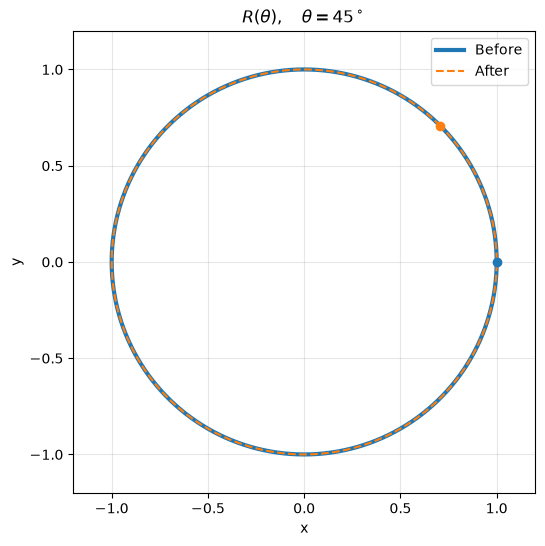

In [4]:
# Overlay the original and rotated unit circles.

fig, ax = plt.subplots(figsize=(6, 6))
# A rotation preserves the unit circle; dashed styling reveals the overlap.
ax.plot(*unit_circle, color="tab:blue", linewidth=3, label="Before")
ax.plot(*rotated_circle, color="tab:orange", linestyle="--", label="After")
# Mark the same point, initially (1, 0), before and after rotation.
ax.scatter(*unit_circle[:, 0], color="tab:blue", zorder=3)
ax.scatter(*rotated_circle[:, 0], color="tab:orange", zorder=3)
# Use the same scale on both axes to keep the circle round.
ax.set_aspect("equal")
ax.set(xlim=(-1.2, 1.2), ylim=(-1.2, 1.2), xlabel="x", ylabel="y")
ax.set_title(r"$R(\theta),\quad \theta = 45^\circ$")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

## Unit Circle Scaling

In [5]:
# Build and apply the scaling matrix S(2, 0.5).

S = np.array([
    [2.0, 0.0],
    [0.0, 0.5],
])
# Scale x by 2 and y by 0.5: (2, 2) @ (2, 361) -> (2, 361).
scaled_circle = S @ unit_circle

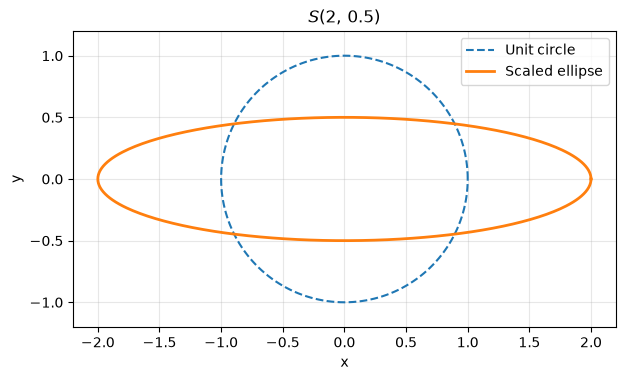

In [6]:
# Compare the unit circle with the scaled ellipse.

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(*unit_circle, color="tab:blue", linestyle="--", label="Unit circle")
ax.plot(*scaled_circle, color="tab:orange", linewidth=2, label="Scaled ellipse")
# Keep identical axis scales to show the ellipse's true proportions.
ax.set_aspect("equal")
ax.set(xlim=(-2.2, 2.2), ylim=(-1.2, 1.2), xlabel="x", ylabel="y")
ax.set_title(r"$S(2,\,0.5)$")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

## Unit Circle Shear

In [7]:
# Build and apply a horizontal shear matrix.

k = 1.0
Sh = np.array([
    [1.0, k],
    [0.0, 1.0],
])
# Map (x, y) to (x + k * y, y); the output shape remains (2, 361).
sheared_circle = Sh @ unit_circle

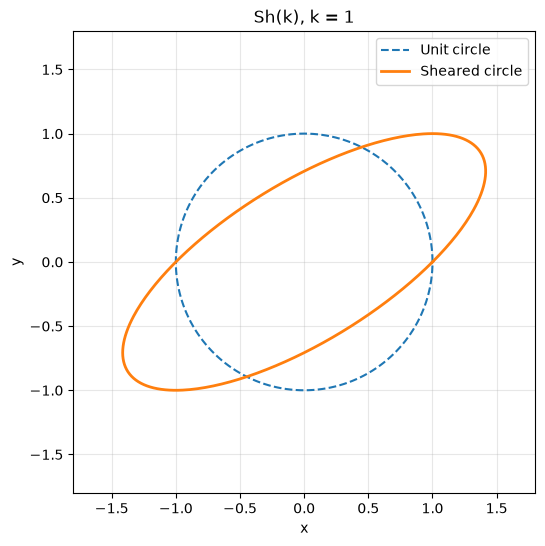

In [8]:
# Compare the unit circle with its sheared shape.

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(*unit_circle, color="tab:blue", linestyle="--", label="Unit circle")
ax.plot(*sheared_circle, color="tab:orange", linewidth=2, label="Sheared circle")
# Keep identical axis scales to show the shear without display distortion.
ax.set_aspect("equal")
ax.set(xlim=(-1.8, 1.8), ylim=(-1.8, 1.8), xlabel="x", ylabel="y")
ax.set_title(f"Sh(k), k = {k:g}")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

## Determinant and Area Ratio

area ratio의 theoretical value는 $|\det(A)|$입니다. 원본과 transformation 후 shape 모두 boundary point에 shoelace formula를 적용해 polygon area로 계산합니다. area ratio는 transformation 후 polygon area를 원본 polygon area로 나눈 값입니다.

relative error는 $\frac{\left|\text{area ratio} - |\det(A)|\right|}{|\det(A)|} \times 100$으로 계산하고, 1% 이하인지 확인합니다. 동일한 boundary point에 transformation을 적용하므로 relative error는 주로 floating-point 계산에서 발생합니다.

In [9]:
# Define an area calculation for ordered polygon boundary points.

# Use the shoelace formula for a (2, N) array of ordered vertices.
def polygon_area(points):
    x, y = points
    # Pair each vertex with its successor, wrapping the last back to the first.
    cross_terms = x * np.roll(y, -1) - y * np.roll(x, -1)
    return float(0.5 * np.abs(np.sum(cross_terms)))

In [10]:
# Compare determinants with area ratios measured from transformed points.

# Measure both original and transformed polygons with the same boundary samples.
original_area = polygon_area(unit_circle)
transformations = [
    ("Rotation", R, rotated_circle),
    ("Scaling", S, scaled_circle),
    ("Shear", Sh, sheared_circle),
]
area_results = []
for name, A, transformed_points in transformations:
    determinant = float(np.linalg.det(A))
    # The absolute determinant gives the area factor, regardless of orientation.
    expected_ratio = abs(determinant)
    transformed_area = polygon_area(transformed_points)
    area_ratio = transformed_area / original_area
    # These three matrices are nonsingular, so expected_ratio is nonzero.
    error_percent = abs(area_ratio - expected_ratio) / expected_ratio * 100
    area_results.append({
        "name": name,
        "determinant": determinant,
        "transformed_area": transformed_area,
        "area_ratio": area_ratio,
        "error_percent": error_percent,
    })

In [11]:
# Display the comparisons and verify a relative error of at most 1%.

print(f"Original polygon area: {original_area:.8f}")
print(f"{'Transform':<10} {'det(A)':>10} {'Area after':>12} {'Area ratio':>12} {'Error (%)':>12} {'Result':>8}")
for result in area_results:
    status = "PASS" if result["error_percent"] <= 1.0 else "FAIL"
    print(
        f"{result['name']:<10} {result['determinant']:>10.6f} "
        f"{result['transformed_area']:>12.6f} {result['area_ratio']:>12.6f} "
        f"{result['error_percent']:>12.3e} {status:>8}"
    )

assert all(result["error_percent"] <= 1.0 for result in area_results), (
    "An area ratio differs from |det(A)| by more than 1%."
)
print("All transformations are within 1% relative error.")

Original polygon area: 3.14143316
Transform      det(A)   Area after   Area ratio    Error (%)   Result
Rotation     1.000000     3.141433     1.000000    3.331e-14     PASS
Scaling      1.000000     3.141433     1.000000    0.000e+00     PASS
Shear        1.000000     3.141433     1.000000    4.441e-14     PASS
All transformations are within 1% relative error.


## Power Iteration

Power Iteration은 absolute value가 가장 큰 eigenvalue와 대응 eigenvector를 구합니다. 아래 예제는 positive eigenvalue를 갖는 symmetric matrix를 사용하므로, 구한 값이 largest eigenvalue입니다.

$$
v_{k+1} = \frac{A v_k}{\|A v_k\|_2}, \qquad
\lambda_k = \frac{v_k^\top A v_k}{v_k^\top v_k}
$$

absolute value가 가장 큰 eigenvalue가 하나이고, initial vector가 대응 eigenvector의 direction으로 component를 가져야 convergence를 기대할 수 있습니다. normalized vector에 대해 $\|A v - \lambda v\|_2 \leq \text{tolerance} \cdot \|A\|_\infty$이면 convergence로 판단합니다.

In [12]:
# Implement Power Iteration for a real matrix with a unique dominant eigenvalue.

# Estimate the dominant eigenpair with normalized products and a residual check.
def power_iteration(A, initial_vector, tolerance=1e-10, max_iterations=1000):
    A = np.asarray(A, dtype=float)
    vector = np.asarray(initial_vector, dtype=float)
    if A.ndim != 2 or A.shape[0] != A.shape[1]:
        raise ValueError("A must be a square matrix.")
    if vector.shape != (A.shape[0],):
        raise ValueError("The initial vector must match the matrix dimension.")
    vector_norm = np.linalg.norm(vector)
    if vector_norm == 0:
        raise ValueError("The initial vector must be nonzero.")
    vector = vector / vector_norm
    matrix_norm = np.linalg.norm(A, ord=np.inf)
    product = A @ vector

    for iteration in range(1, max_iterations + 1):
        product_norm = np.linalg.norm(product)
        if product_norm == 0:
            raise ValueError("A @ vector is zero; choose a different initial vector.")
        # Normalization controls vector size while preserving its direction.
        vector = product / product_norm
        product = A @ vector
        # For a unit vector, the Rayleigh quotient is v.T @ A @ v.
        eigenvalue = float(vector @ product)
        residual_norm = np.linalg.norm(product - eigenvalue * vector)
        # A residual check also works when a negative eigenvalue flips the sign.
        if residual_norm <= tolerance * matrix_norm:
            return eigenvalue, vector, iteration, float(residual_norm)

    raise RuntimeError("Power Iteration did not converge within max_iterations.")

In [13]:
# Prepare a symmetric positive-definite matrix and an initial vector.

A_power = np.array([
    [4.0, 1.0],
    [1.0, 3.0],
])
initial_vector = np.array([1.0, 0.0])

In [14]:
# Estimate the largest eigenvalue of the example matrix.

power_value, power_vector, power_iterations, power_residual = power_iteration(
    A_power, initial_vector
)

In [15]:
# Display the estimated eigenpair and compare the eigenvalue with NumPy.

# eigvalsh returns real eigenvalues for a symmetric matrix.
reference_value = float(np.max(np.linalg.eigvalsh(A_power)))
print(f"Estimated dominant eigenvalue: {power_value:.12f}")
print(f"NumPy reference eigenvalue:    {reference_value:.12f}")
print(f"Estimated eigenvector: {power_vector}")
print(f"Iterations: {power_iterations}")
print(f"Residual norm: {power_residual:.3e}")
print(f"Absolute eigenvalue error: {abs(power_value - reference_value):.3e}")
assert np.isclose(power_value, reference_value, rtol=1e-8, atol=1e-10), (
    "Power Iteration does not match the NumPy reference eigenvalue."
)
print("Power Iteration matches the NumPy reference.")

Estimated dominant eigenvalue: 4.618033988750
NumPy reference eigenvalue:    4.618033988750
Estimated eigenvector: [0.85065081 0.52573111]
Iterations: 33
Residual norm: 4.490e-10
Absolute eigenvalue error: 8.882e-16
Power Iteration matches the NumPy reference.


## SVD Image Compression

input은 `assets/images/camera.png`의 512×512 grayscale image입니다.
pixel value는 PNG를 읽을 때 `[0, 1]` 범위의 real number로 변환됩니다.

image matrix $A \in \mathbb{R}^{m \times n}$에 대해 다음 decomposition을 사용합니다.

$$
A = U\Sigma V^\top, \qquad
A_k = U_{[:, :k]}\Sigma_{[:k, :k]}V^\top_{[:k, :]}
    = \sum_{i=1}^{k}\sigma_i u_i v_i^\top
$$

singular value가 큰 순서대로 상위 $k$개 component만 저장하면, 원본의 $mn$개 대신
$mk + k + kn = k(m+n+1)$개의 numerical value로 image를 표현할 수 있습니다.
아래 storage ratio는 numerical value 개수의 ratio이며, data type의 byte 수나 PNG 파일 크기의 ratio는 아닙니다.

`k=10, 50, 100`의 reconstruction 결과를 원본과 동일한 intensity range로 비교합니다.
mean squared error는 $\mathrm{MSE} = \frac{1}{mn}\sum_{i,j}(A_{ij} - (A_k)_{ij})^2$입니다.
error는 reconstructed matrix 그대로 계산하고, visualization할 때만 `[0, 1]` 범위로 잘라 표시합니다.

In [16]:
# Load the grayscale PNG from the project root or the src directory.

project_root = Path.cwd()
if not (project_root / "assets" / "images" / "camera.png").is_file():
    project_root = project_root.parent
image_path = project_root / "assets" / "images" / "camera.png"
# Use float64 to reduce rounding error during SVD and error measurement.
image = plt.imread(image_path).astype(np.float64)
k_values = (10, 50, 100)
print(f"Input image: {image_path.relative_to(project_root)}")
print(f"Image shape: {image.shape}; pixel range: [{image.min():.1f}, {image.max():.1f}]")

Input image: assets/images/camera.png
Image shape: (512, 512); pixel range: [0.0, 1.0]


In [17]:
# Define SVD compression and reconstruction for a grayscale image matrix.

# Keep only the leading k singular components as a compressed representation.
def compress_image_svd(image, k):
    """Return truncated U, singular values, and Vt for a 2D image."""
    image = np.asarray(image, dtype=float)
    if image.ndim != 2 or 0 in image.shape:
        raise ValueError("The image must be a nonempty 2D grayscale matrix.")
    if not np.isfinite(image).all():
        raise ValueError("Image values must be finite.")
    if not isinstance(k, (int, np.integer)) or not 1 <= k <= min(image.shape):
        raise ValueError("k must be an integer between 1 and min(image.shape).")
    # Reduced SVD: U (m, r), s (r,), Vt (r, n), where r = min(m, n).
    U, singular_values, Vt = np.linalg.svd(image, full_matrices=False)
    # Copies prevent the compressed arrays from retaining full factors in memory.
    return U[:, :k].copy(), singular_values[:k].copy(), Vt[:k, :].copy()


# Reconstruct A_k = U_k @ diag(s_k) @ Vt_k from the compressed factors.
def reconstruct_image_svd(U_k, singular_values_k, Vt_k):
    """Reconstruct an image matrix from its truncated SVD factors."""
    # Broadcasting scales each U_k column: (m, k) * (k,), then @ (k, n).
    return (U_k * singular_values_k) @ Vt_k

In [18]:
# Compress and reconstruct the image at each requested rank.

# Factorize once; smaller ranks use the leading components of the k=100 factors.
U_svd, singular_values_svd, Vt_svd = compress_image_svd(image, max(k_values))
compressed_images = {}
reconstructed_images = {}
svd_results = []
for rank in k_values:
    compressed_images[rank] = (
        U_svd[:, :rank].copy(),
        singular_values_svd[:rank].copy(),
        Vt_svd[:rank, :].copy(),
    )
    reconstructed_images[rank] = reconstruct_image_svd(*compressed_images[rank])
    stored_values = sum(factor.size for factor in compressed_images[rank])
    svd_results.append({
        "k": rank,
        "stored_values": stored_values,
        "value_ratio": stored_values / image.size,
        "mse": float(np.mean((image - reconstructed_images[rank]) ** 2)),
    })

In [19]:
# Compare reconstruction error and the number of stored values.

print(f"Original image: {image.size:,} values")
print(f"{'k':>5} {'Stored values':>15} {'Values (%)':>12} {'MSE':>14}")
for result in svd_results:
    print(
        f"{result['k']:>5} {result['stored_values']:>15,} "
        f"{100 * result['value_ratio']:>12.2f} {result['mse']:>14.8f}"
    )
# More singular components should reduce approximation error for this image.
errors = np.array([result["mse"] for result in svd_results])
assert np.all(np.diff(errors) < 0), "MSE must decrease as k increases."
assert all(result["value_ratio"] < 1 for result in svd_results), (
    "Each compressed representation must use fewer values than the original."
)
print("MSE decreases as k increases; all three representations use fewer values.")

Original image: 262,144 values
    k   Stored values   Values (%)            MSE
   10          10,250         3.91     0.00619086
   50          51,250        19.55     0.00137203
  100         102,500        39.10     0.00052522
MSE decreases as k increases; all three representations use fewer values.


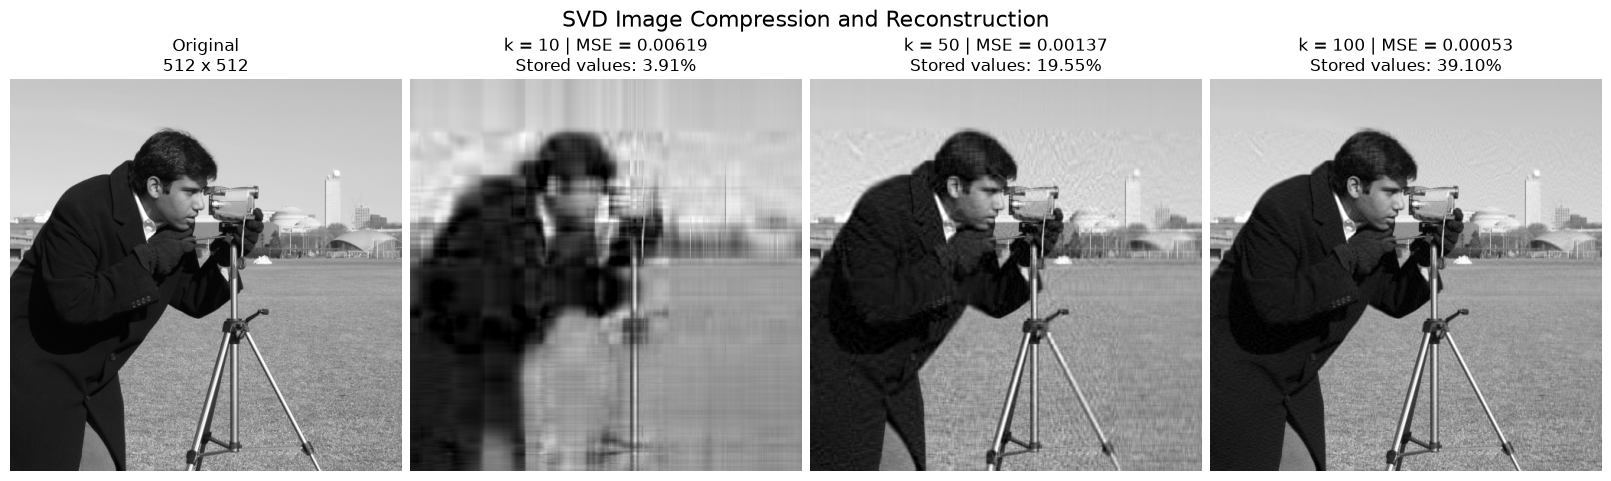

In [20]:
# Display the original and three reconstructions in one Figure.

fig, axes = plt.subplots(1, 4, figsize=(16, 5), layout="constrained")
axes[0].imshow(image, cmap="gray", vmin=0, vmax=1)
axes[0].set_title(f"Original\n{image.shape[0]} x {image.shape[1]}")
for ax, result in zip(axes[1:], svd_results, strict=True):
    # Fix the display range so auto-contrast cannot hide reconstruction differences.
    display_image = np.clip(reconstructed_images[result["k"]], 0, 1)
    ax.imshow(display_image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(
        f"k = {result['k']} | MSE = {result['mse']:.5f}\n"
        f"Stored values: {100 * result['value_ratio']:.2f}%"
    )
for ax in axes:
    ax.axis("off")
fig.suptitle("SVD Image Compression and Reconstruction", fontsize=16)
plt.show()